# 2장 2강: 퍼널 분석 — 전환율·이탈률 측정 원리 — 실습문제

## 실습 목표

- Ravenstack의 구독 여정을 순차적인 퍼널 단계로 정의할 수 있다.
- 이벤트 횟수와 고유 구독 수의 차이를 설명할 수 있다.
- 단계별 전환율과 이탈률을 계산할 수 있다.
- 막대형 퍼널을 시각화하고 이탈이 집중된 구간을 찾을 수 있다.
- 세그먼트별 퍼널을 비교하고 개선 가설을 제안할 수 있다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- `ravenstack_subscriptions.csv`
- `ravenstack_feature_usage.csv`

이번 실습에서는 Ravenstack의 구독 여정을 다음과 같이 단순화합니다.

| 순서 | 퍼널 단계 | 집계 기준 |
|---:|---|---|
| 1 | 구독 시작 | `subscriptions`에 존재하는 고유 구독 |
| 2 | 기능 사용 | 기능 사용 기록이 한 번 이상 있는 구독 |
| 3 | 유료 구독 | 기능 사용 구독 중 `is_trial == False`인 구독 |
| 4 | 현재 유료 유지 | 이전 단계 구독 중 `end_date`가 비어 있는 구독 |

> 이 퍼널은 전환율 계산 원리를 익히기 위한 학습용 정의입니다. `is_trial`은 실제 유료 전환 시각을 기록한 이벤트가 아니므로 실제 전환 소요 시간이나 행동 순서를 완전히 재구성할 수는 없습니다.

## 실습 준비

1. 필요한 라이브러리를 불러오세요.
2. 두 CSV 파일을 각각 `subscriptions`, `feature_usage`에 불러오세요.
3. 각 데이터의 행과 열 개수, 상위 5개 행을 확인하세요.
4. 분석 대상 컬럼의 자료형과 결측치 개수를 확인하세요.
5. `start_date`, `end_date`, `usage_date`를 날짜형으로 변환하세요.
6. 구독 ID의 고유 개수와 기능 사용 이벤트 행 수를 확인하세요.
7. `usage_id`의 중복 개수를 확인하고, 중복 ID를 바로 삭제하면 안 되는 이유를 생각해보세요.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정 (환경에 맞게 변경: Windows 'Malgun Gothic', Mac 'AppleGothic')
for name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in {f.name for f in fm.fontManager.ttflist}:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False

# 1~2. 데이터 불러오기
subscriptions = pd.read_csv('ravenstack_subscriptions.csv')
feature_usage = pd.read_csv('ravenstack_feature_usage.csv')

# 3. 크기와 상위 5행
print('subscriptions:', subscriptions.shape)
display(subscriptions.head())
print('feature_usage:', feature_usage.shape)
display(feature_usage.head())

# 4. 분석 대상 컬럼의 자료형과 결측치
sub_cols = ['subscription_id', 'start_date', 'end_date', 'plan_tier', 'is_trial', 'billing_frequency']
use_cols = ['usage_id', 'subscription_id', 'usage_date']
display(pd.DataFrame({'dtype': subscriptions[sub_cols].dtypes, 'null_count': subscriptions[sub_cols].isna().sum()}))
display(pd.DataFrame({'dtype': feature_usage[use_cols].dtypes, 'null_count': feature_usage[use_cols].isna().sum()}))

# 5. 날짜형 변환
subscriptions['start_date'] = pd.to_datetime(subscriptions['start_date'])
subscriptions['end_date'] = pd.to_datetime(subscriptions['end_date'])
feature_usage['usage_date'] = pd.to_datetime(feature_usage['usage_date'])

# 6. 고유 구독 수 vs 이벤트 행 수
print('고유 구독 ID 수:', subscriptions['subscription_id'].nunique())
print('기능 사용 이벤트 행 수:', len(feature_usage))
print('기능 사용 기록이 있는 고유 구독 수:', feature_usage['subscription_id'].nunique())

# 7. usage_id 중복 확인
dup_cnt = feature_usage['usage_id'].duplicated().sum()
print('usage_id 중복 개수:', dup_cnt)
display(feature_usage[feature_usage['usage_id'].duplicated(keep=False)].sort_values('usage_id').head(6))

subscriptions: (5000, 14)


,subscription_id,account_id,start_date,end_date,plan_tier,seats,mrr_amount,arr_amount,is_trial,upgrade_flag,downgrade_flag,churn_flag,billing_frequency,auto_renew_flag
0,S-8cec59,A-3c1a3f,2023-12-23,2024-04-12,Enterprise,14,2786,33432,False,False,False,True,monthly,True
1,S-0f6f44,A-9b9fe9,2024-06-11,NaN,Pro,17,833,9996,False,False,False,False,monthly,True
2,S-51c0d1,A-659280,2024-11-25,NaN,Enterprise,62,0,0,True,True,False,False,annual,False
3,S-f81687,A-e7a1e2,2024-11-23,2024-12-13,Enterprise,5,995,11940,False,False,False,True,monthly,True
4,S-cff5a2,A-ba6516,2024-01-10,NaN,Enterprise,27,5373,64476,False,False,False,False,monthly,True


feature_usage: (25000, 8)


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
0,U-1c6c24,S-0fcf7d,2023-07-27,feature_20,9,5004,0,False
1,U-f07cb8,S-c25263,2023-08-07,feature_5,9,369,0,False
2,U-096807,S-f29e7f,2023-12-07,feature_3,9,1458,0,False
3,U-6b1580,S-be655e,2024-07-28,feature_40,5,2085,0,False
4,U-720a29,S-f9b1d0,2024-12-02,feature_12,12,900,0,False


,dtype,null_count
subscription_id,str,0
start_date,str,0
end_date,str,4514
plan_tier,str,0
is_trial,bool,0
billing_frequency,str,0


,dtype,null_count
usage_id,str,0
subscription_id,str,0
usage_date,str,0


고유 구독 ID 수: 5000
기능 사용 이벤트 행 수: 25000
기능 사용 기록이 있는 고유 구독 수: 4967
usage_id 중복 개수: 21


,usage_id,subscription_id,usage_date,feature_name,usage_count,usage_duration_secs,error_count,is_beta_feature
19294,U-0c9318,S-01b2dc,2023-12-11,feature_9,5,1060,3,False
17533,U-0c9318,S-0ffab0,2024-01-30,feature_11,3,1614,0,False
20588,U-13ce5b,S-9b623b,2023-03-26,feature_28,10,2050,1,False
9626,U-13ce5b,S-8b0950,2024-09-10,feature_9,8,824,0,True
18480,U-2103bb,S-7fc49b,2023-04-18,feature_12,9,5022,1,False
10379,U-2103bb,S-ae3270,2024-01-06,feature_3,10,5510,0,False


> **usage_id 중복을 바로 삭제하면 안 되는 이유**: 중복된 `usage_id` 행을 살펴보면 **서로 다른 구독(subscription_id)·날짜·기능**을 가진 별개의 이벤트입니다. 즉 "같은 행이 두 번 적재된 것"이 아니라 ID 생성 과정의 충돌일 가능성이 큽니다. ID만 보고 삭제하면 실제 사용 기록이 사라져 퍼널 단계 수가 왜곡될 수 있으므로, 모든 컬럼이 동일한 완전 중복인지 먼저 확인해야 합니다. (이번 퍼널은 구독 ID의 고유 개수로 집계하므로 이 중복의 영향도 받지 않습니다.)

---

## 필수 1. 전체 구독 퍼널의 전환율과 이탈률 계산하기

### 문제 1-1. Ravenstack 구독은 어느 구간에서 가장 많이 이탈하는가?

#### 문제 설명

전체 Ravenstack 구독을 대상으로 네 단계의 고유 구독 수를 계산하고, 각 구간의 전환율과 이탈률을 구하세요.

각 단계는 반드시 앞 단계를 통과한 구독만 포함해야 합니다. 예를 들어 유료 구독 단계는 전체 유료 구독이 아니라 **기능 사용 단계에 포함되면서 유료인 구독**으로 계산합니다.

#### 요구사항

1. 전체 구독 ID를 `started_ids`로 만드세요.
2. 기능 사용 기록이 있는 구독 ID와 `started_ids`의 교집합을 `used_ids`로 만드세요.
3. `used_ids`와 체험이 아닌 구독 ID의 교집합을 `paid_ids`로 만드세요.
4. `paid_ids`와 종료일이 비어 있는 구독 ID의 교집합을 `retained_paid_ids`로 만드세요.
5. 단계명과 고유 구독 수를 사용하여 `funnel` 데이터프레임을 만드세요.
6. 다음 식으로 구간 전환율과 이탈률을 계산하세요.
   - 전환율 = 현재 단계 구독 수 ÷ 이전 단계 구독 수
   - 이탈률 = 1 - 전환율
7. 각 구간의 이탈 구독 수도 계산하세요.
8. 단계별 구독 수를 막대그래프로 시각화하세요.
9. 전환율이 가장 낮은 구간을 찾고 개선 가설을 한 가지 제안하세요.

#### 해석 질문

**Q1.** 기능 사용 이벤트 행 수 대신 고유 구독 수를 사용해야 하는 이유는 무엇인가요?  
**Q2.** 전환율이 가장 낮고 이탈 구독 수가 가장 많은 구간은 어디인가요?  
**Q3.** 전환율과 이탈률을 더하면 얼마인가요?  
**Q4.** 낮은 전환율만으로 실제 이탈 원인을 확정할 수 있나요?

#### 제출 결과

- 단계별 고유 구독 집합
- `funnel` 데이터프레임
- 전환율·이탈률·이탈 구독 수
- 막대형 퍼널
- 이탈 집중 구간과 개선 가설
- Q1~Q4 답변

,stage,subscriptions,prev_subscriptions,conversion_rate,drop_rate,dropped_subscriptions,overall_rate
0,구독 시작,5000,-,-,-,-,100.0%
1,기능 사용,4967,5000,99.3%,0.7%,33,99.3%
2,유료 구독,4193,4967,84.4%,15.6%,774,83.9%
3,현재 유료 유지,3788,4193,90.3%,9.7%,405,75.8%


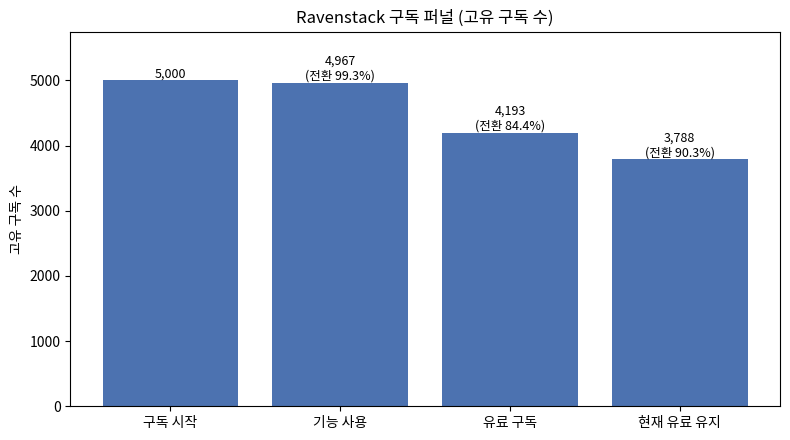

전환율 최저 구간: 기능 사용 → 유료 구독 | 전환율 84.4%, 이탈률 15.6%, 이탈 774건
전환율 + 이탈률 = [1.]


In [2]:
# 1~4. 단계별 고유 구독 집합 (각 단계는 이전 단계의 부분집합)
started_ids = set(subscriptions['subscription_id'])
used_ids = set(feature_usage['subscription_id']) & started_ids
paid_ids = used_ids & set(subscriptions.loc[~subscriptions['is_trial'], 'subscription_id'])
retained_paid_ids = paid_ids & set(subscriptions.loc[subscriptions['end_date'].isna(), 'subscription_id'])

stages = ['구독 시작', '기능 사용', '유료 구독', '현재 유료 유지']

# 5. funnel 데이터프레임
funnel = pd.DataFrame({
    'stage': stages,
    'subscriptions': [len(started_ids), len(used_ids), len(paid_ids), len(retained_paid_ids)]
})

# 6~7. 구간 전환율 / 이탈률 / 이탈 구독 수
funnel['prev_subscriptions'] = funnel['subscriptions'].shift(1)
funnel['conversion_rate'] = funnel['subscriptions'] / funnel['prev_subscriptions']
funnel['drop_rate'] = 1 - funnel['conversion_rate']
funnel['dropped_subscriptions'] = funnel['prev_subscriptions'] - funnel['subscriptions']
funnel['overall_rate'] = funnel['subscriptions'] / funnel['subscriptions'].iloc[0]
display(funnel.style.format({'prev_subscriptions': '{:.0f}', 'conversion_rate': '{:.1%}', 'drop_rate': '{:.1%}',
                             'dropped_subscriptions': '{:.0f}', 'overall_rate': '{:.1%}'}, na_rep='-'))

# 8. 막대형 퍼널
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(funnel['stage'], funnel['subscriptions'], color='#4C72B0')
for i, b in enumerate(bars):
    label = f"{int(b.get_height()):,}"
    if i > 0:
        label += f"\n(전환 {funnel.loc[i, 'conversion_rate']:.1%})"
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), label, ha='center', va='bottom', fontsize=9)
ax.set_title('Ravenstack 구독 퍼널 (고유 구독 수)')
ax.set_ylabel('고유 구독 수')
ax.set_ylim(0, funnel['subscriptions'].max() * 1.15)
plt.tight_layout(); plt.show()

# 9. 전환율이 가장 낮은 구간
steps = funnel.dropna(subset=['conversion_rate']).copy()
steps['transition'] = funnel['stage'].shift(1).dropna() + ' → ' + steps['stage']
worst = steps.loc[steps['conversion_rate'].idxmin()]
print(f"전환율 최저 구간: {worst['transition']} | 전환율 {worst['conversion_rate']:.1%}, "
      f"이탈률 {worst['drop_rate']:.1%}, 이탈 {worst['dropped_subscriptions']:.0f}건")
print('전환율 + 이탈률 =', (steps['conversion_rate'] + steps['drop_rate']).round(10).unique())

### 필수 1 답변 작성란

**결과 요약**: 구독 시작 5,000 → 기능 사용 4,967(99.3%) → 유료 구독 4,193(84.4%) → 현재 유료 유지 3,788(90.3%)

**이탈 집중 구간**: `기능 사용 → 유료 구독` (전환율 84.4%, 이탈률 15.6%, 이탈 774건)

**개선 가설**: 기능을 사용해 본 체험 구독이 유료로 넘어가지 못하는 것은 *체험 기간 안에 핵심 가치(유료에서만 얻는 기능·효과)를 충분히 경험하지 못하기 때문*일 수 있다. → 체험 중 핵심 기능 온보딩 가이드와 체험 종료 전 사용 성과 요약 + 전환 안내를 제공하면 유료 전환율이 오를 것이다.

- **Q1.** 이벤트 행 수는 "얼마나 많이 사용했는가(빈도)"를 세므로, 헤비 유저 한 구독이 수백 행을 만들면 단계 규모가 부풀려집니다. 퍼널은 "몇 개의 구독이 이 단계에 도달했는가"를 보는 것이므로 한 구독을 한 번만 세는 고유 구독 수를 써야 단계 간 비교(전환율)가 의미를 갖습니다. 실제로 이벤트는 25,000행이지만 기능을 사용한 고유 구독은 4,967개입니다.
- **Q2.** `기능 사용 → 유료 구독` 구간입니다. 전환율이 84.4%로 가장 낮고, 이탈 구독 수도 774건으로 가장 많습니다(시작→사용 33건, 유료→유지 405건).
- **Q3.** 항상 1(100%)입니다. 이탈률을 `1 - 전환율`로 정의했기 때문에, 이전 단계 구독은 "다음 단계로 넘어갔다" 또는 "넘어가지 못했다" 둘 중 하나로만 분류됩니다.
- **Q4.** 없습니다. 퍼널은 **어디서** 빠지는지를 보여줄 뿐 **왜** 빠지는지는 알려주지 않습니다. 또한 이번 퍼널은 `is_trial` 상태로 단순화한 학습용 정의라 실제 전환 시점·순서도 알 수 없습니다. 원인을 확정하려면 이탈 구독의 기능 사용 패턴·오류 수, 이탈 사유(churn_events), 사용자 인터뷰, A/B 테스트 등으로 가설을 검증해야 합니다.

---

## 필수 2. 요금제별 퍼널 비교하기

### 문제 2-1. 요금제에 따라 이탈 구간이 다른가?

#### 문제 설명

`Basic`, `Pro`, `Enterprise` 요금제별로 동일한 퍼널을 계산하고 구간 전환율을 비교하세요. 그룹별 비교를 통해 특정 요금제에 문제가 집중되어 있는지 확인합니다.

#### 요구사항

1. 요금제별 퍼널을 계산하는 함수 `calculate_segment_funnel()`을 작성하세요.
2. 함수는 필수 1과 동일한 네 단계의 고유 구독 수와 구간 전환율을 반환해야 합니다.
3. 세 요금제의 결과를 결합하여 `plan_funnel`을 만드세요.
4. 첫 단계를 제외한 구간별 전환율을 요금제별 막대그래프로 시각화하세요.
5. 모든 요금제와 구간의 조합 중 전환율이 가장 낮은 조합을 찾으세요.
6. 해당 요금제와 구간을 우선 점검 대상으로 정하고 개선 가설을 한 가지 제안하세요.
7. 요금제별 차이가 크지 않을 경우 해석에서 그 사실도 언급하세요.

#### 해석 질문

**Q1.** 전환율이 가장 낮은 요금제와 구간의 조합은 무엇인가요?  
**Q2.** 요금제별 퍼널 비교가 전체 퍼널만 보는 것보다 유용한 이유는 무엇인가요?  
**Q3.** 관찰된 요금제별 차이는 큰 편인가요?  
**Q4.** 개선 가설을 확인하기 위해 어떤 데이터를 추가로 살펴볼 수 있나요?

#### 제출 결과

- 요금제별 퍼널 계산 함수
- `plan_funnel` 결과
- 요금제별 전환율 그래프
- 우선 점검 대상과 개선 가설
- Q1~Q4 답변

,segment,stage,step,subscriptions,conversion_rate,drop_rate,transition
0,Basic,구독 시작,1,1602,-,-,-
1,Basic,기능 사용,2,1588,99.13%,0.87%,구독 시작 → 기능 사용
2,Basic,유료 구독,3,1343,84.57%,15.43%,기능 사용 → 유료 구독
3,Basic,현재 유료 유지,4,1217,90.62%,9.38%,유료 구독 → 현재 유료 유지
4,Pro,구독 시작,1,1675,-,-,-
5,Pro,기능 사용,2,1665,99.40%,0.60%,구독 시작 → 기능 사용
6,Pro,유료 구독,3,1407,84.50%,15.50%,기능 사용 → 유료 구독
7,Pro,현재 유료 유지,4,1273,90.48%,9.52%,유료 구독 → 현재 유료 유지
8,Enterprise,구독 시작,1,1723,-,-,-
9,Enterprise,기능 사용,2,1714,99.48%,0.52%,구독 시작 → 기능 사용


segment,Basic,Pro,Enterprise
transition,,,
구독 시작 → 기능 사용,99.13%,99.40%,99.48%
기능 사용 → 유료 구독,84.57%,84.50%,84.19%
유료 구독 → 현재 유료 유지,90.62%,90.48%,89.95%


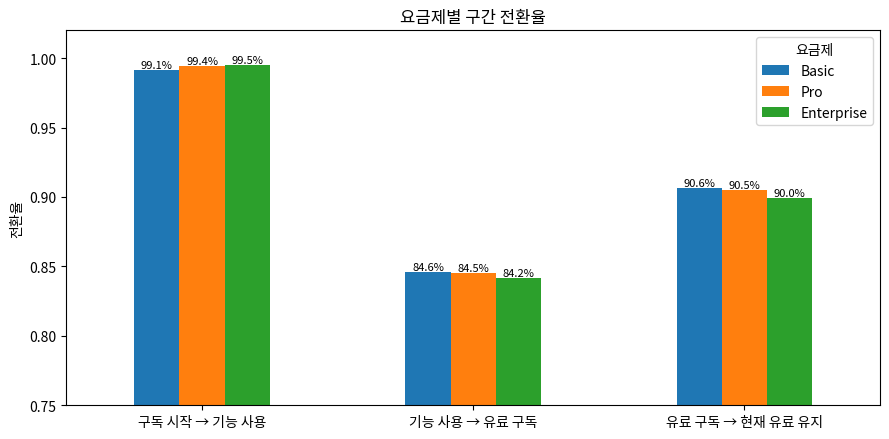

최저 조합: Enterprise / 기능 사용 → 유료 구독 — 전환율 84.19%, 이탈률 15.81%

구간별 요금제 간 전환율 격차(%p):
transition
구독 시작 → 기능 사용       0.35
기능 사용 → 유료 구독       0.38
유료 구독 → 현재 유료 유지    0.67
dtype: float64


In [3]:
def calculate_segment_funnel(sub_df, usage_df, segment_col, segment_value):
    """특정 세그먼트의 4단계 퍼널(고유 구독 수 + 구간 전환율)을 계산한다."""
    seg = sub_df[sub_df[segment_col] == segment_value]
    started = set(seg['subscription_id'])
    used = set(usage_df['subscription_id']) & started
    paid = used & set(seg.loc[~seg['is_trial'], 'subscription_id'])
    retained = paid & set(seg.loc[seg['end_date'].isna(), 'subscription_id'])

    result = pd.DataFrame({
        'segment': segment_value,
        'stage': stages,
        'step': range(1, 5),
        'subscriptions': [len(started), len(used), len(paid), len(retained)]
    })
    result['conversion_rate'] = result['subscriptions'] / result['subscriptions'].shift(1)
    result['drop_rate'] = 1 - result['conversion_rate']
    result['transition'] = result['stage'].shift(1) + ' → ' + result['stage']
    return result

plans = ['Basic', 'Pro', 'Enterprise']
plan_funnel = pd.concat([calculate_segment_funnel(subscriptions, feature_usage, 'plan_tier', p) for p in plans],
                        ignore_index=True)
display(plan_funnel.style.format({'conversion_rate': '{:.2%}', 'drop_rate': '{:.2%}'}, na_rep='-'))

# 구간 × 요금제 전환율 표
plan_pivot = (plan_funnel.dropna(subset=['conversion_rate'])
              .pivot(index='transition', columns='segment', values='conversion_rate')
              .reindex(index=plan_funnel['transition'].dropna().unique(), columns=plans))
display(plan_pivot.style.format('{:.2%}'))

# 4. 요금제별 구간 전환율 막대그래프
ax = plan_pivot.plot(kind='bar', figsize=(9, 4.5), rot=0)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v:.1%}' for v in c.datavalues], fontsize=8)
ax.set_title('요금제별 구간 전환율')
ax.set_ylabel('전환율'); ax.set_xlabel('')
ax.set_ylim(0.75, 1.02)
ax.legend(title='요금제')
plt.tight_layout(); plt.show()

# 5. 전환율이 가장 낮은 요금제 × 구간
steps_plan = plan_funnel.dropna(subset=['conversion_rate'])
w = steps_plan.loc[steps_plan['conversion_rate'].idxmin()]
print(f"최저 조합: {w['segment']} / {w['transition']} — 전환율 {w['conversion_rate']:.2%}, 이탈률 {w['drop_rate']:.2%}")

# 7. 요금제 간 차이 크기 확인 (구간별 최대-최소, %p)
print('\n구간별 요금제 간 전환율 격차(%p):')
print(((plan_pivot.max(axis=1) - plan_pivot.min(axis=1)) * 100).round(2))

### 필수 2 답변 작성란

**우선 점검 대상**: `Enterprise` 요금제의 `기능 사용 → 유료 구독` 구간 (전환율 약 84.2%, 이탈률 약 15.8%)

**개선 가설**: Enterprise는 좌석 수가 많고 도입 결정권자가 여러 명이라, 체험 중 소수 담당자만 기능을 써보고 조직 차원의 도입 가치를 입증하지 못해 유료 계약이 지연·무산될 수 있다. → 체험 단계에서 전담 CSM의 도입 지원(팀 단위 온보딩, ROI 리포트)을 제공하면 전환율이 오를 것이다.

단, 세 요금제의 이 구간 전환율은 84.2%~84.6%로 **격차가 0.4%p 수준에 불과**하여 요금제 고유의 문제라기보다 전 요금제 공통의 체험→유료 전환 문제로 보는 것이 타당합니다.

- **Q1.** `Enterprise` × `기능 사용 → 유료 구독` (전환율 약 84.2%)입니다.
- **Q2.** 전체 퍼널은 여러 그룹이 섞인 평균이라 특정 그룹의 문제가 다른 그룹의 좋은 성과에 가려질 수 있습니다. 세그먼트로 나누면 문제가 특정 그룹에 집중되어 있는지(→ 타깃 개선), 전체 공통인지(→ 제품 전반 개선)를 구분해 개선 우선순위와 대상을 정할 수 있습니다.
- **Q3.** 크지 않습니다. 모든 구간에서 요금제 간 전환율 격차가 0.4~0.7%p로 1%p 미만이고, 세 요금제 모두 `기능 사용 → 유료 구독`이 가장 약한 동일한 패턴을 보입니다. 구독 수 규모(요금제당 약 1,600~1,700건)를 고려하면 이 정도 차이는 우연에 의한 변동일 가능성도 있어, 통계적 검정 없이 "Enterprise가 특히 나쁘다"고 결론 내리기 어렵습니다.
- **Q4.** ① `feature_usage`에서 전환/미전환 구독의 기능 사용 빈도·사용 시간·`error_count`·사용 기능 종류 비교, ② `seats`·`mrr_amount` 등 규모별 전환율, ③ 계정(`accounts`)의 산업·국가·유입 채널, ④ 이탈 사유(churn/지원 티켓) 데이터, ⑤ 체험 시작~종료 기간과 전환 시점 이벤트 로그 등을 추가로 확인할 수 있습니다.

---

## 과제 1. 평가 문항 기반 독립 과제

### 문제 3-1. 결제 주기별 퍼널 비교하기

#### 문제 설명

월간 결제 구독과 연간 결제 구독의 퍼널을 비교하여 상대적으로 전환율이 낮은 그룹과 구간을 찾으세요.

> 이 과제는 필수 2에서 만든 함수와 분석 절차를 `billing_frequency`에 동일하게 적용하는 문제입니다.

#### 요구사항

1. `calculate_segment_funnel()`을 사용하여 `monthly`, `annual`의 퍼널을 계산하세요.
2. 두 결과를 결합하여 `billing_funnel`을 만드세요.
3. 첫 단계를 제외한 구간 전환율을 결제 주기별 막대그래프로 시각화하세요.
4. 모든 결제 주기와 구간의 조합 중 전환율이 가장 낮은 조합을 찾으세요.
5. 해당 그룹과 구간에 대한 개선 가설을 한 가지 제안하세요.
6. 퍼널 결과만으로 원인을 확정할 수 없는 이유와 추가 확인할 데이터를 설명하세요.

#### 해석 질문

**Q1.** 전환율이 가장 낮은 결제 주기와 구간의 조합은 무엇인가요?  
**Q2.** 해당 구간의 전환율과 이탈률은 얼마인가요?  
**Q3.** 이 결과만으로 결제 주기가 이탈의 원인이라고 말할 수 있나요?

#### 제출 결과

- `billing_funnel` 결과
- 결제 주기별 전환율 그래프
- 우선 점검 대상과 개선 가설
- 분석의 한계와 추가 확인 데이터
- Q1~Q3 답변

,segment,stage,step,subscriptions,conversion_rate,drop_rate,transition
0,monthly,구독 시작,1,2539,-,-,-
1,monthly,기능 사용,2,2520,99.25%,0.75%,구독 시작 → 기능 사용
2,monthly,유료 구독,3,2120,84.13%,15.87%,기능 사용 → 유료 구독
3,monthly,현재 유료 유지,4,1930,91.04%,8.96%,유료 구독 → 현재 유료 유지
4,annual,구독 시작,1,2461,-,-,-
5,annual,기능 사용,2,2447,99.43%,0.57%,구독 시작 → 기능 사용
6,annual,유료 구독,3,2073,84.72%,15.28%,기능 사용 → 유료 구독
7,annual,현재 유료 유지,4,1858,89.63%,10.37%,유료 구독 → 현재 유료 유지


segment,monthly,annual
transition,,
구독 시작 → 기능 사용,99.25%,99.43%
기능 사용 → 유료 구독,84.13%,84.72%
유료 구독 → 현재 유료 유지,91.04%,89.63%


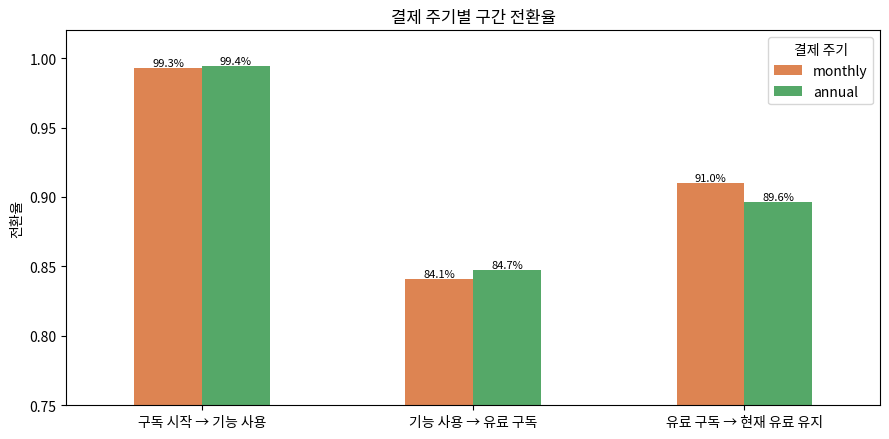

최저 조합: monthly / 기능 사용 → 유료 구독 — 전환율 84.13%, 이탈률 15.87%

구간별 결제 주기 간 전환율 격차(%p):
transition
구독 시작 → 기능 사용       0.18
기능 사용 → 유료 구독       0.59
유료 구독 → 현재 유료 유지    1.41
dtype: float64


In [4]:
# 1~2. 결제 주기별 퍼널
billings = ['monthly', 'annual']
billing_funnel = pd.concat([calculate_segment_funnel(subscriptions, feature_usage, 'billing_frequency', b) for b in billings],
                           ignore_index=True)
display(billing_funnel.style.format({'conversion_rate': '{:.2%}', 'drop_rate': '{:.2%}'}, na_rep='-'))

billing_pivot = (billing_funnel.dropna(subset=['conversion_rate'])
                 .pivot(index='transition', columns='segment', values='conversion_rate')
                 .reindex(index=billing_funnel['transition'].dropna().unique(), columns=billings))
display(billing_pivot.style.format('{:.2%}'))

# 3. 결제 주기별 구간 전환율 그래프
ax = billing_pivot.plot(kind='bar', figsize=(9, 4.5), rot=0, color=['#DD8452', '#55A868'])
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v:.1%}' for v in c.datavalues], fontsize=8)
ax.set_title('결제 주기별 구간 전환율')
ax.set_ylabel('전환율'); ax.set_xlabel('')
ax.set_ylim(0.75, 1.02)
ax.legend(title='결제 주기')
plt.tight_layout(); plt.show()

# 4. 전환율이 가장 낮은 결제 주기 × 구간
steps_bill = billing_funnel.dropna(subset=['conversion_rate'])
wb = steps_bill.loc[steps_bill['conversion_rate'].idxmin()]
print(f"최저 조합: {wb['segment']} / {wb['transition']} — 전환율 {wb['conversion_rate']:.2%}, 이탈률 {wb['drop_rate']:.2%}")
print('\n구간별 결제 주기 간 전환율 격차(%p):')
print(((billing_pivot.max(axis=1) - billing_pivot.min(axis=1)) * 100).round(2))

### 과제 1 답변 작성란

**우선 점검 대상**: `monthly`(월간 결제) × `기능 사용 → 유료 구독` 구간

**개선 가설**: 월간 결제는 초기 결제 부담은 작지만 "언제든 다시 생각해도 된다"는 인식 때문에 체험 후 결제를 미루기 쉽다. → 체험 종료 시점에 첫 달 할인이나 연간 전환 시 혜택을 명확히 제시하면 월간 그룹의 유료 전환율이 오를 것이다.

**분석의 한계와 추가 확인 데이터**: 퍼널은 결과(어디서 빠지는가)만 보여줄 뿐, 결제 주기와 전환 사이의 인과를 보여주지 않습니다. 결제 주기는 사용자가 **스스로 선택**한 속성이라 조직 규모·예산·도입 의지 등 다른 요인과 얽혀 있을 수 있고(교란 변수), `is_trial`·`end_date`는 상태값일 뿐 전환 시점 이벤트가 아닙니다. 두 그룹의 격차도 약 0.6%p로 작습니다. 추가로 ① 요금제·좌석 수를 통제한 결제 주기별 전환율, ② 두 그룹의 기능 사용 강도·오류 수, ③ 체험 기간과 전환 시점 이벤트 로그, ④ 이탈 사유·설문, ⑤ 결제 옵션 안내 방식을 바꾼 A/B 테스트 결과를 확인해야 합니다.

- **Q1.** `monthly` × `기능 사용 → 유료 구독` 조합입니다.
- **Q2.** 전환율 약 84.13%(2,520 → 2,120), 이탈률 약 15.87%(400건 이탈)입니다. 비교 대상인 annual의 같은 구간은 약 84.72%입니다.
- **Q3.** 말할 수 없습니다. 격차가 0.6%p로 작아 우연일 수 있고, 결제 주기는 무작위 배정이 아니라 사용자가 선택한 것이므로 요금제·조직 규모 같은 다른 요인이 차이를 만들었을 수 있습니다. 상관관계일 뿐 인과관계를 주장하려면 통제 분석이나 실험이 필요합니다.

---

## 실습 마무리

아래 질문에 답하세요.

1. 이번 실습의 퍼널 단계를 어떻게 정의했나요?
2. 단계별 사용자 수 대신 어떤 식별자의 고유 개수를 사용했나요?
3. 전환율과 이탈률은 어떻게 계산했나요?
4. 전체 퍼널에서 가장 큰 문제가 나타난 구간은 어디였나요?
5. 퍼널 분석 결과와 실제 원인을 왜 구분해야 하나요?

### 실습 마무리 답변

1. **퍼널 정의**: 구독 시작(전체 고유 구독) → 기능 사용(기능 사용 기록 1회 이상) → 유료 구독(그중 `is_trial == False`) → 현재 유료 유지(그중 `end_date` 결측). 각 단계는 이전 단계의 부분집합(교집합)으로 정의했습니다.
2. **식별자**: 사용자(account) 수나 이벤트 행 수가 아니라 `subscription_id`의 고유 개수를 사용했습니다.
3. **계산식**: 구간 전환율 = 현재 단계 구독 수 ÷ 이전 단계 구독 수, 이탈률 = 1 − 전환율, 이탈 구독 수 = 이전 단계 − 현재 단계.
4. **가장 큰 문제 구간**: `기능 사용 → 유료 구독` (전환율 84.4%, 이탈 774건). 요금제·결제 주기 세그먼트에서도 모두 동일하게 가장 약한 구간이었습니다.
5. **결과와 원인 구분 이유**: 퍼널은 "어디서" 이탈하는지만 알려주는 관측 결과이고 "왜"는 알려주지 않습니다. 원인을 추정으로 확정하면 잘못된 개선에 자원을 쓰게 되므로, 퍼널로 문제 구간을 찾고 → 가설을 세우고 → 추가 데이터·실험으로 검증하는 순서를 지켜야 합니다.